# 1. Libraries

In [111]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
from scipy.optimize import curve_fit, minimize

# 2. Functions

In [112]:
def filter_function_bi(t, t1, t2, rho_):
    rho = 1 - rho_
    norm = np.max( np.abs( (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)) ) )
    return ((t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)))/norm


def filter_function_bi_minimize_2(tau):
    t1 = tau[0]
    t2 = tau[1]
    rho = 1 - tau[2]
    t = np.copy(data[:,0])
    norm = np.max( np.abs( (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)) ) )
    filter_ = ((t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)))/norm
    area_ = np.sum( 0.5*(np.roll(filter_, -1) + filter_)[:-1]*(np.roll(t, -1) - t)[:-1] )
    error = np.sum((filter_[1:] - filter_exp[1:])**2)/t.size + np.sum((filter_[0] - filter_exp[0])**2)
    return error


def error_function(tau):
    t1 = tau[0]
    t2 = tau[1]
    rho = 1 - tau[2]
    t = np.copy(data[:,0])
    norm = np.max( np.abs( (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)) ) )
    filter_ = ((t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)))/norm
    area_ = np.sum( 0.5*(np.roll(filter_, -1) + filter_)[:-1]*(np.roll(t, -1) - t)[:-1] )
    area_model_abs = np.sum( 0.5*(np.abs(np.roll(filter_,-1)) + np.abs(filter_))[:-1]*(np.roll(t,-1) - t)[:-1] )
    area_model_cum = np.cumsum( 0.5*(np.abs(np.roll(filter_,-1)) + np.abs(filter_))[:-1]*(np.roll(t,-1) - t)[:-1] )
    idx_half_area = np.where(area_model_cum >= area_model_abs/2)[0][0]
    Time_scale_half_model = t_array[idx_half_area]
    error = np.sum((filter_[1:] - filter_exp[1:])**2)/t.size + np.sum((filter_[0] - filter_exp[0])**2)
    return error


def area_function(tau):
    t1 = tau[0]
    t2 = tau[1]
    rho = 1 - tau[2]
    t = np.copy(data[:,0])
    norm = np.max( np.abs( (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)) ) )
    filter_ = ((t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) - (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2)))/norm
    return np.sum( 0.5*(np.roll(filter_, -1) + filter_)[:-1]*(np.roll(t, -1) - t)[:-1] )

# 3. Motion detection pathway

## 3.1 Load data

In [ ]:
path_to_data_motion = "user-path-to-motion-data"

# file format: Filter_ExpIntep_<name>.txt  (2-column: time, filter)
string_motion      = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm1_OFF', 'Tm2_OFF', 'Tm4_OFF', 'Tm9_OFF']
string_plot_motion = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm1',     'Tm2',     'Tm4',     'Tm9'    ]
N_neurons_motion   = len(string_motion)

# biphasic (|integral| < 0.5): fixed rho = 1.9  → rho_ = -0.9
# monophasic (|integral| > 0.5): fixed rho = -1.9 → rho_ = 2.9
Neurons_bi_motion   = np.array([0, 1, 3, 5, 7, 8, 9])
Neurons_mono_motion = np.array([2, 4, 6, 10])

## 3.2 Plot filters

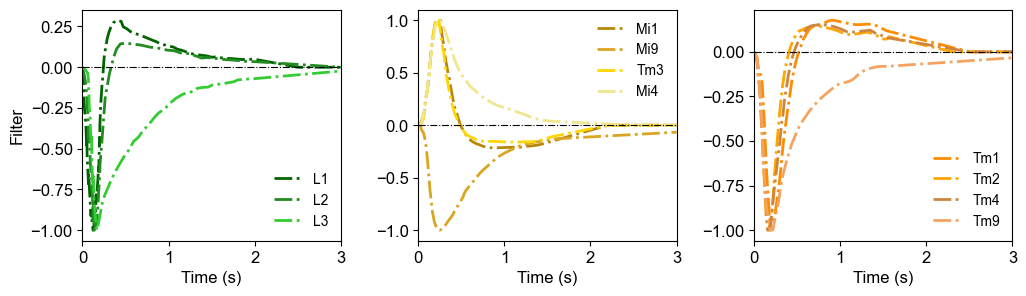

In [114]:
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size']   = 12

exp1 = 4
exp2 = 3

# Column 0 → Lamina (greens), Column 1 → ON Medulla (yellows), Column 2 → OFF Medulla (oranges)
groups = [
    {'label': 'Lamina',      'idx': [0, 1, 2],    'colors': ['darkgreen',    'forestgreen', 'limegreen']},
    {'label': 'ON Medulla',  'idx': [3, 4, 5, 6],    'colors': ['darkgoldenrod','goldenrod',   'gold',       'khaki'       ]},
    {'label': 'OFF Medulla', 'idx': [7, 8, 9, 10],  'colors': ['darkorange',   'orange',      'peru',       'sandybrown'  ]},
]

Fig, ax = plt.subplots(1, 3, figsize=(12, 3))
Fig.subplots_adjust(wspace=0.3)

for col_idx, grp in enumerate(groups):
    for j, i_neuron in enumerate(grp['idx']):
        data = np.loadtxt(path_to_data_motion + '/Filter_ExpIntep_' + string_motion[i_neuron] + '.txt')
        polarity = np.abs(np.max(data[:,1])) - np.abs(np.min(data[:,1]))
        if polarity < 0:
            data[:,1] *= 1
        data[:,1] /= np.max(np.abs(data[:,1]))
        ax[col_idx].plot(data[:,0], data[:,1], color=grp['colors'][j], linewidth=2, linestyle = '-.',
                         label=string_plot_motion[i_neuron])
    ax[col_idx].axhline(y=0, color='k', linestyle='-.', linewidth=0.8)
    ax[col_idx].set_xlabel('Time (s)', fontsize=12)
    ax[col_idx].set_xlim(0, 3)
    ax[col_idx].legend(fontsize=10, frameon=False)
    if col_idx == 0:
        ax[col_idx].set_ylabel('Filter', fontsize=12)

plt.show()

## 3.3 Fit filters

In [115]:
np.random.seed(1)

exp1 = 4
exp2 = 3

# rho fixed via tight bounds: biphasic rho=1.9 → rho_=-0.9; monophasic rho=-1.9 → rho_=2.9
rho_bi_fixed   = -0.9
rho_mono_fixed =  2.9

# Per-neuron initial parameter ranges: (t1_lo, t1_hi, t2_lo, t2_hi)
tau_init_motion = {
    'L1':     (0.02, 0.06, 0.10, 0.25),
    'L2':     (0.02, 0.08, 0.15, 0.38),
    'L3':     (0.04, 0.15, 0.20, 0.55),
    'Mi1':    (0.04, 0.12, 0.20, 0.48),
    'Mi9':    (0.06, 0.18, 0.30, 0.70),
    'Tm3':    (0.03, 0.12, 0.18, 0.50),
    'Mi4':    (0.04, 0.14, 0.15, 0.45),
    'Tm1_OFF':(0.04, 0.12, 0.20, 0.50),
    'Tm2_OFF':(0.02, 0.09, 0.18, 0.45),
    'Tm4_OFF':(0.03, 0.10, 0.20, 0.48),
    'Tm9_OFF':(0.04, 0.14, 0.20, 0.50),
}

best_popt_motion    = np.zeros((N_neurons_motion, 3))
error_mean_motion   = np.zeros(N_neurons_motion)
error_std_arr_motion = np.zeros(N_neurons_motion)
exp_data_motion     = {}

for i_neuron in range(N_neurons_motion):

    if np.any(i_neuron == Neurons_bi_motion):
        N_tau0    = 100
        rho_fixed = rho_bi_fixed
    else:
        N_tau0    = 50
        rho_fixed = rho_mono_fixed

    # load and prepare data once per neuron
    data_ref = np.loadtxt(path_to_data_motion + '/Filter_ExpIntep_' + string_motion[i_neuron] + '.txt')
    polarity = np.abs(np.max(data_ref[:,1])) - np.abs(np.min(data_ref[:,1]))
    if polarity < 0:
        data_ref[:,1] *= -1
    data_ref[:,1] /= np.max(np.abs(data_ref[:,1]))

    area_ref     = np.sum(0.5*(np.roll(data_ref[:,1],-1) + data_ref[:,1])[:-1]*(np.roll(data_ref[:,0],-1) - data_ref[:,0])[:-1])
    area_abs_ref = np.sum(0.5*(np.abs(np.roll(data_ref[:,1],-1)) + np.abs(data_ref[:,1]))[:-1]*(np.roll(data_ref[:,0],-1) - data_ref[:,0])[:-1])
    area_cum_ref = np.cumsum(0.5*(np.abs(np.roll(data_ref[:,1],-1)) + np.abs(data_ref[:,1]))[:-1]*(np.roll(data_ref[:,0],-1) - data_ref[:,0])[:-1])
    idx_half     = np.where(area_cum_ref >= area_abs_ref/2)[0][0]
    print('Neuron:', string_motion[i_neuron], '| Area =', area_ref, '| Half-life =', data_ref[idx_half, 0])

    t1_lo, t1_hi, t2_lo, t2_hi = tau_init_motion[string_motion[i_neuron]]

    error_array2 = np.zeros(N_tau0)
    popt_array2  = np.zeros((N_tau0, 3))

    for time_init1 in range(N_tau0):
        data       = data_ref
        filter_exp = data[:,1]
        area_exp   = area_ref
        t_array    = data[:,0]

        Tau0 = np.array([np.random.uniform(t1_lo, t1_hi),
                         np.random.uniform(t2_lo, t2_hi),
                         rho_fixed])
        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                        bounds=((0.001, 0.3), (0.01, 0.7),
                                (rho_fixed - 0.9, rho_fixed + 0.1)),
                        method='Powell')
        popt2 = res2.x
        popt_array2[time_init1, :] = popt2
        error_array2[time_init1]   = error_function(popt2)

    idx_min2 = np.where(error_array2 == np.min(error_array2))[0][0]
    best_popt_motion[i_neuron, :]    = popt_array2[idx_min2, :]
    error_mean_motion[i_neuron]      = np.mean(error_array2)
    error_std_arr_motion[i_neuron]   = np.std(error_array2)
    exp_data_motion[i_neuron]        = data_ref.copy()

    print('Fit params:', best_popt_motion[i_neuron, :])
    #np.savetxt(path_to_data_motion + '/' + string_motion[i_neuron] + '_filter_parameters_polished_2.txt', best_popt_motion[i_neuron, :])

Neuron: L1 | Area = -0.0963655450636886 | Half-life = 0.454
Fit params: [ 0.03825417  0.18065134 -1.8       ]
Neuron: L2 | Area = -0.018214415158237074 | Half-life = 0.437
Fit params: [ 0.04414044  0.2774711  -1.56305789]
Neuron: L3 | Area = 0.6580090235329055 | Half-life = 0.557
Fit params: [0.08290832 0.37443997 3.        ]
Neuron: Mi1 | Area = -0.014253476783263285 | Half-life = 0.591
Fit params: [ 0.07259777  0.34355386 -1.8       ]
Neuron: Mi9 | Area = 0.8556951365423122 | Half-life = 0.638
Fit params: [0.10549305 0.53102527 3.        ]
Neuron: Tm3 | Area = 0.022691790801289576 | Half-life = 0.377
Fit params: [ 0.06753294  0.34380723 -1.49059219]
Neuron: Mi4 | Area = 0.5229685523607324 | Half-life = 0.41200000000000003
Fit params: [0.08073311 0.29886597 3.        ]
Neuron: Tm1_OFF | Area = 0.020650030682707172 | Half-life = 0.41600000000000004
Fit params: [ 0.07071805  0.37237728 -1.5428478 ]
Neuron: Tm2_OFF | Area = 0.02210131256313824 | Half-life = 0.309
Fit params: [ 0.05368459

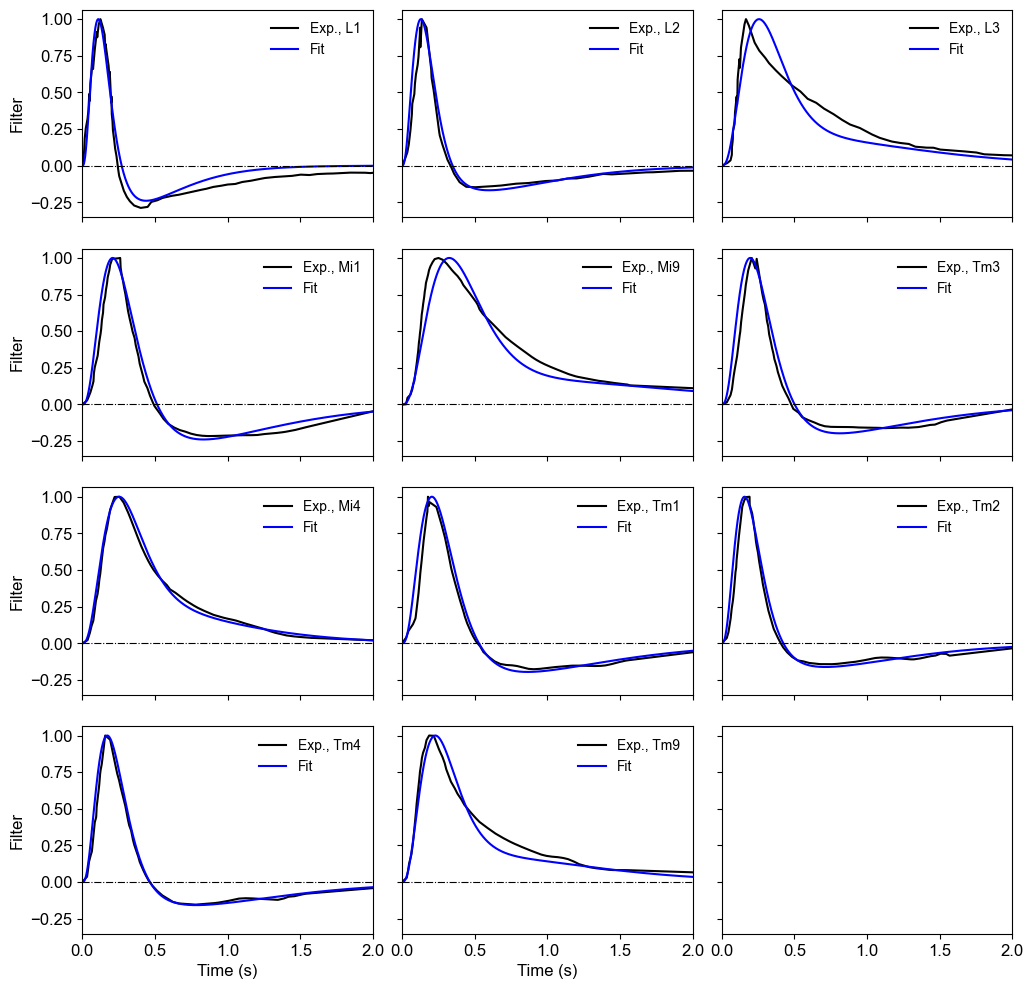

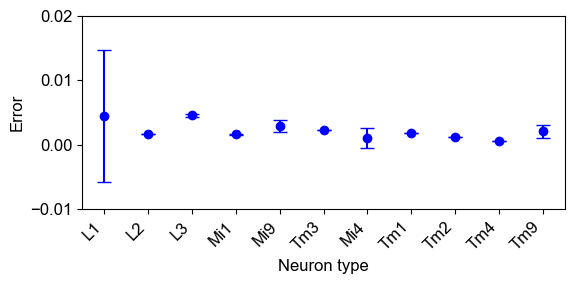

In [127]:
# --- Global font + export settings ---
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']   # force Arial
matplotlib.rcParams['font.size'] = 12

# Ensure text stays as editable text in Illustrator (not outlines)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# Optional but helpful for consistency
matplotlib.rcParams['axes.titlesize'] = 12
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12

# Figure 1: experimental trace (black) and fit (blue) per neuron
n_cols = 3
n_rows = int(np.ceil(N_neurons_motion / n_cols))
Fig1, axes1 = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows),
                            sharex=True, sharey=True)
Fig1.subplots_adjust(wspace=0.1, hspace=0.15)

for i_neuron in range(N_neurons_motion):
    row = i_neuron // n_cols
    col = i_neuron % n_cols
    ax  = axes1[row, col]
    t_ax  = exp_data_motion[i_neuron][:,0]
    f_ax  = exp_data_motion[i_neuron][:,1]
    ax.plot(t_ax, f_ax, color='k', linewidth=1.5,
            label='Exp., ' + string_plot_motion[i_neuron])
    fit = filter_function_bi(t_ax, best_popt_motion[i_neuron,0],
                                   best_popt_motion[i_neuron,1],
                                   best_popt_motion[i_neuron,2])
    ax.plot(t_ax, fit, color='b', linewidth=1.5, label='Fit')
    ax.axhline(y=0, color='k', linestyle='-.', linewidth=0.8)
    ax.set_xlim(0, 2)
    ax.legend(fontsize=10, frameon=False)
    if row == n_rows - 1:
        ax.set_xlabel('Time (s)', fontsize=12)
    if col == 0:
        ax.set_ylabel('Filter', fontsize=12)
plt.savefig("FitFilters_motionpathway.pdf", bbox_inches='tight', dpi=300)
plt.show()

# Figure 2: error mean +/- std across random initializations, all neurons
Fig2, ax2 = plt.subplots(1, figsize=(6, 3))
x_pos = np.arange(N_neurons_motion)
ax2.errorbar(x_pos, error_mean_motion, yerr=error_std_arr_motion,
             fmt='o', color='b', capsize=5, linewidth=1.5, markersize=6)
ax2.set_xticks(x_pos)
ax2.set_ylim(-0.01,0.02)
ax2.set_xticklabels(string_plot_motion, rotation=45, ha='right', fontsize=12)
ax2.set_ylabel('Error', fontsize=12)
ax2.set_xlabel('Neuron type', fontsize=12)
plt.tight_layout()
plt.savefig("ErrorFitFilters_motionpathway.pdf", bbox_inches='tight', dpi=300)
plt.show()

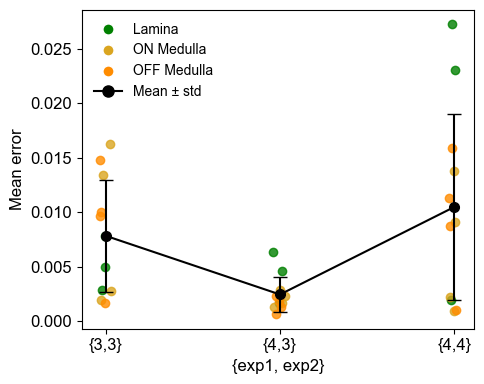

In [ ]:
# Compute mean error for each neuron across filter orders (exp1,exp2) = (3,3),(4,3),(4,4)
np.random.seed(1)
rho_bi_fixed   = -0.9
rho_mono_fixed =  2.9

orders       = [(3, 3), (4, 3), (4, 4)]
order_labels = ['{3,3}', '{4,3}', '{4,4}']

error_mean_orders = np.zeros((len(orders), N_neurons_motion))

for i_order, (e1, e2) in enumerate(orders):
    exp1 = e1; exp2 = e2
    for i_neuron in range(N_neurons_motion):
        if np.any(i_neuron == Neurons_bi_motion):
            N_tau0 = 100; rho_fixed = rho_bi_fixed
        else:
            N_tau0 = 50;  rho_fixed = rho_mono_fixed

        t1_lo, t1_hi, t2_lo, t2_hi = tau_init_motion[string_motion[i_neuron]]

        data_ref = np.loadtxt(path_to_data_motion + '/Filter_ExpIntep_' + string_motion[i_neuron] + '.txt')
        polarity = np.abs(np.max(data_ref[:,1])) - np.abs(np.min(data_ref[:,1]))
        if polarity < 0:
            data_ref[:,1] *= -1
        data_ref[:,1] /= np.max(np.abs(data_ref[:,1]))

        error_array = np.zeros(N_tau0)
        for time_init1 in range(N_tau0):
            data       = data_ref
            filter_exp = data[:,1]
            t_array    = data[:,0]
            Tau0 = np.array([np.random.uniform(t1_lo, t1_hi),
                             np.random.uniform(t2_lo, t2_hi),
                             rho_fixed])
            res = minimize(filter_function_bi_minimize_2, Tau0,
                           bounds=((0.001, 0.3), (0.01, 0.7),
                                   (rho_fixed - 0.9, rho_fixed + 0.1)),
                           method='Powell')
            error_array[time_init1] = error_function(res.x)

        error_mean_orders[i_order, i_neuron] = np.mean(error_array)



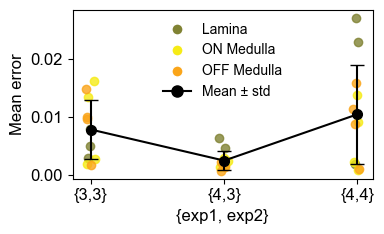

In [145]:
# --- Summary plot: all neurons in one panel, mean ± std in black ---
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size']   = 12

groups_order = [
    {'label': 'Lamina',      'idx': [0, 1, 2],     'color': '#808233'     },
    {'label': 'ON Medulla',  'idx': [3, 4, 5, 6],  'color': '#f6eb16' },
    {'label': 'OFF Medulla', 'idx': [7, 8, 9, 10], 'color': '#faa51a'},
]

x_pos        = np.arange(len(orders))
jitter_scale = 0.08

Fig, ax = plt.subplots(1, figsize=(4, 2.5))

np.random.seed(2)
for grp in groups_order:
    for i_neuron in grp['idx']:
        jitter = (np.random.rand(len(orders)) - 0.5) * jitter_scale
        ax.plot(x_pos + jitter, error_mean_orders[:, i_neuron],
                'o', color=grp['color'], alpha=0.8, markersize=6)

mean_all = np.mean(error_mean_orders, axis=1)
std_all  = np.std(error_mean_orders, axis=1)
ax.errorbar(x_pos, mean_all, yerr=std_all,
            fmt='o-', color='k', capsize=5, linewidth=1.5, markersize=7, zorder=5)

ax.set_xticks(x_pos)
ax.set_xticklabels(order_labels, fontsize=12)
ax.set_xlabel('{exp1, exp2}', fontsize=12)
ax.set_ylabel('Mean error', fontsize=12)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#808233',      markersize=8, label='Lamina'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#f6eb16',  markersize=8, label='ON Medulla'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#faa51a', markersize=8, label='OFF Medulla'),
    Line2D([0],[0], marker='o', color='k', markersize=8, linewidth=1.5,  label='Mean \u00b1 std'),
]
ax.legend(handles=legend_elements, fontsize=10, frameon=False)
plt.tight_layout()
plt.savefig("MeanError_BiphasicOrder.pdf", bbox_inches = 'tight', dpi = 300)
plt.show()

# 4. Outside motion detection pathway (Clandinin)

## 4.1 Load data

In [ ]:
path_to_data = "user-path-to-data"

string = ['Mi2', 'Tm12', 'Tm20', 'Tm34', 'Tm5b', 'TmY10', 'TmY14', 'TmY3', 'TmY5a']
Neurons_bi_array   = np.array([0, 1, 2, 3, 5, 6, 7])
Neurons_mono_array = np.array([4])
Pol_array  = [-1, 1, -1, 1, 1, -1, -1, 1, -1]
N_neurons  = len(string)
T_array    = np.loadtxt(path_to_data + '/Clandinin/Filter_ExpIntep_time.txt')

## 4.2 Plot filters

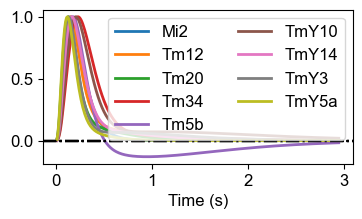

In [118]:
exp1 = 4
exp2 = 3
N_neurons = len(string)
T_array   = np.loadtxt(path_to_data + '/Clandinin/Filter_ExpIntep_time.txt')

matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size']   = 12

Fig, ax = plt.subplots(1, figsize=(4, 2))
counter = -1
for cell_type in string:
    counter += 1
    pars = np.loadtxt(path_to_data + '/Clandinin/' + str(string[counter]) + '_filter_parameters_polished_2.txt')
    fil  = filter_function_bi(T_array, pars[0], pars[1], 1-pars[2])
    plt.plot(T_array, fil, label=str(cell_type), linewidth=2)
    plt.legend(ncol=2)
    plt.xlabel('Time (s)')
    plt.axhline(y=0, color='k', linestyle='-.')
plt.show()

## 4.3 Fit filters

In [119]:
np.random.seed(1)

exp1 = 4
exp2 = 3

# Per-neuron initial parameter ranges: (t1_lo, t1_hi, t2_lo, t2_hi, rho_lo, rho_hi)
tau_init_cland = {
    'Mi2':   (0.02, 0.10, 0.05, 0.16, -2.5, -0.5),
    'Tm12':  (0.02, 0.09, 0.10, 0.30, -2.0,  0.0),
    'Tm20':  (0.02, 0.09, 0.04, 0.15, -2.0, -0.5),
    'Tm34':  (0.04, 0.14, 0.06, 0.18, -2.0, -0.5),
    'Tm5b':  (0.02, 0.12, 0.25, 0.65,  1.5,  3.5),
    'TmY10': (0.04, 0.14, 0.07, 0.20, -2.0, -0.5),
    'TmY14': (0.03, 0.10, 0.05, 0.15, -2.0, -0.5),
    'TmY3':  (0.02, 0.09, 0.10, 0.30, -1.5,  0.5),
    'TmY5a': (0.01, 0.08, 0.02, 0.08,  1.0,  3.0),
}

best_popt     = np.zeros((N_neurons, 3))
error_mean    = np.zeros(N_neurons)
error_std_arr = np.zeros(N_neurons)
exp_data      = {}

for i_order in np.array([1]):
    if i_order == 0:
        exp1 = 3; exp2 = 3
    if i_order == 1:
        exp1 = 4; exp2 = 3
    if i_order == 2:
        exp1 = 4; exp2 = 4

    data = np.zeros((T_array.size, 2))
    data[:, 0] = T_array
    for i_neuron in range(N_neurons):

        if np.any(i_neuron == Neurons_bi_array):
            N_tau0 = 100
        else:
            N_tau0 = 50

        t1_lo, t1_hi, t2_lo, t2_hi, rho_lo, rho_hi = tau_init_cland[string[i_neuron]]

        error_array2 = np.zeros(N_tau0)
        popt_array2  = np.zeros((N_tau0, 3))

        for time_init1 in range(N_tau0):

            data[:, 1] = Pol_array[i_neuron]*np.loadtxt(path_to_data + '/Clandinin/Filter_ExpIntep_' + str(string[i_neuron]) + '.txt')
            data[:, 1] /= np.max(data[:, 1])

            integral_val = np.sum(0.5*(np.roll(data[:,1],-1) + data[:,1])[:-1]*(np.roll(data[:,0],-1) - data[:,0])[:-1])

            if np.abs(integral_val) < 2:
                filter_exp = data[:,1]
                area_exp   = integral_val

                area_exp_abs = np.sum(0.5*(np.abs(np.roll(data[:,1],-1)) + np.abs(data[:,1]))[:-1]*(np.roll(data[:,0],-1) - data[:,0])[:-1])
                area_exp_cum = np.cumsum(0.5*(np.abs(np.roll(data[:,1],-1)) + np.abs(data[:,1]))[:-1]*(np.roll(data[:,0],-1) - data[:,0])[:-1])
                dt_val       = T_array[1] - T_array[0]
                t_array      = np.arange(0, 4, dt_val)
                idx_half_area = np.where(area_exp_cum >= area_exp_abs/2)[0][0]
                Time_scale_half_exp = t_array[idx_half_area]
                if time_init1 == 0:
                    print('Area =', area_exp, '| Half-life =', Time_scale_half_exp)

                if np.any(i_neuron == Neurons_mono_array):
                    if np.logical_and(exp1 == 4, exp2 == 3):
                        Tau0 = np.array([np.random.uniform(t1_lo, t1_hi),
                                         np.random.uniform(t2_lo, t2_hi),
                                         np.random.uniform(rho_lo, rho_hi)])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.005, 0.3), (0.02, 0.5), (0.1, 6)), method='Powell')
                    if np.logical_and(exp1 == 3, exp2 == 3):
                        Tau0 = np.array([np.random.choice(np.arange(0.05, 0.7, 0.01)),
                                         np.random.choice(np.arange(0.05, 0.7, 0.01)),
                                         np.random.choice(np.arange(2,    3.5, 0.1 ))])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.03, 0.7), (0.03, 0.7), (0.1, 6)), method='Powell')
                    if np.logical_and(exp1 == 4, exp2 == 4):
                        Tau0 = np.array([np.random.choice(np.arange(0.01, 0.3, 0.01)),
                                         np.random.choice(np.arange(0.01, 0.3, 0.01)),
                                         np.random.choice(np.arange(2,    3.5, 0.1 ))])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.005, 0.3), (0.005, 0.3), (0.1, 6)), method='Powell')
                else:
                    if np.logical_and(exp1 == 4, exp2 == 3):
                        Tau0 = np.array([np.random.uniform(t1_lo, t1_hi),
                                         np.random.uniform(t2_lo, t2_hi),
                                         np.random.uniform(rho_lo, rho_hi)])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.005, 0.3), (0.02, 0.3), (-4, 4)), method='Powell')
                    if np.logical_and(exp1 == 3, exp2 == 3):
                        Tau0 = np.array([np.random.choice(np.arange(0.05, 0.7, 0.01)),
                                         np.random.choice(np.arange(0.05, 0.7, 0.01)),
                                         np.random.choice(np.arange(-1,   1.5, 0.1 ))])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.03, 0.7), (0.03, 0.7), (-4, 6)), method='Powell')
                    if np.logical_and(exp1 == 4, exp2 == 4):
                        Tau0 = np.array([np.random.choice(np.arange(0.01, 0.3, 0.01)),
                                         np.random.choice(np.arange(0.01, 0.3, 0.01)),
                                         np.random.choice(np.arange(-1,   1.5, 0.1 ))])
                        res2 = minimize(filter_function_bi_minimize_2, Tau0,
                                        bounds=((0.005, 0.3), (0.005, 0.3), (-4, 6)), method='Powell')

                popt2 = res2.x
                popt_array2[time_init1, :] = popt2
                error_array2[time_init1]   = error_function(popt2)

        if np.abs(integral_val) < 1:
            idx_min2 = np.where(error_array2 == np.min(error_array2))[0][0]
            best_popt[i_neuron, :]    = popt_array2[idx_min2, :]
            error_mean[i_neuron]      = np.mean(error_array2)
            error_std_arr[i_neuron]   = np.std(error_array2)
            exp_data[i_neuron]        = data[:, 1].copy()

            print('Neuron type:', string[i_neuron])
            print('Fit params:', best_popt[i_neuron, :])
            #np.savetxt(path_to_data + '/Clandinin/' + string[i_neuron] + '_filter_parameters_polished_2.txt', best_popt[i_neuron, :])

Area = -0.013359516022595677 | Half-life = 0.35000000000000003
Neuron type: Mi2
Fit params: [ 0.05165771  0.09708848 -1.58343762]
Area = 0.007237407401007853 | Half-life = 0.38
Neuron type: Tm12
Fit params: [ 0.05412888  0.09218199 -1.4183883 ]
Area = 0.030573645479208027 | Half-life = 0.25
Neuron type: Tm20
Fit params: [ 0.04866407  0.07835787 -1.24149112]
Area = 0.08480018262646748 | Half-life = 0.44
Neuron type: Tm34
Fit params: [ 0.07803983  0.11223223 -1.33623455]
Area = 0.3856949236994768 | Half-life = 0.3


/var/folders/16/g2scbvkx5w36rhlfb5hhg5m80000gn/T/ipykernel_72648/3268118806.py:71: OptimizeWarning: Initial guess is not within the specified bounds
  res2 = minimize(filter_function_bi_minimize_2, Tau0,


Neuron type: Tm5b
Fit params: [0.05991891 0.46485115 2.44569245]
Area = -0.007144857332499838 | Half-life = 0.51
Neuron type: TmY10
Fit params: [ 0.07950775  0.1258839  -1.41637691]
Area = 0.034636396478488235 | Half-life = 0.28
Neuron type: TmY14
Fit params: [ 0.05954047  0.0968931  -1.30634302]
Area = 0.019052478406850655 | Half-life = 0.3
Neuron type: TmY3
Fit params: [ 0.04429817  0.3        -1.12331318]
Area = 0.05284839128932544 | Half-life = 0.29
Neuron type: TmY5a
Fit params: [ 0.03883406  0.12950295 -0.62396388]


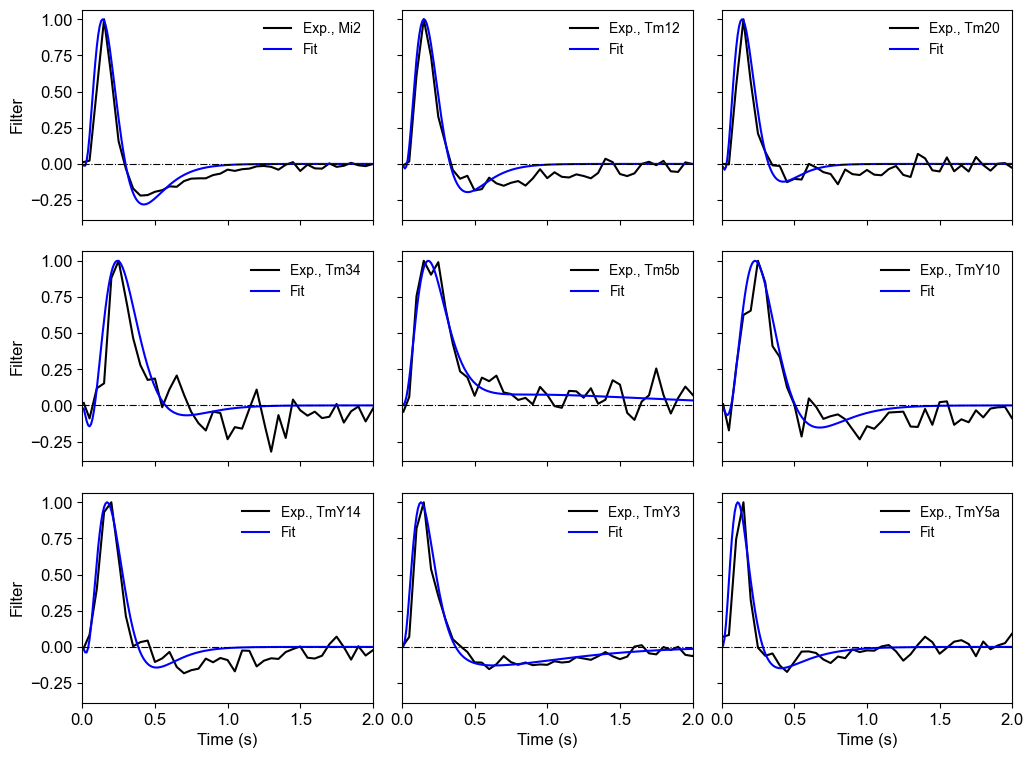

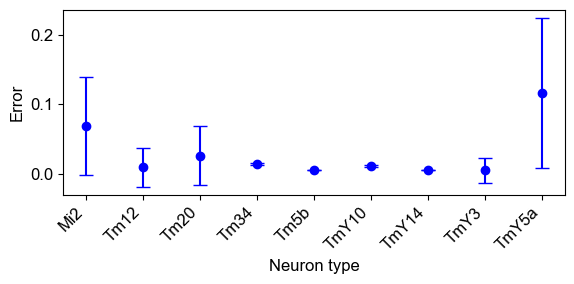

In [122]:
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size']   = 12

# Figure 1: experimental trace (black) and fit (blue) per neuron
n_cols = 3
n_rows = int(np.ceil(N_neurons / n_cols))
Fig1, axes1 = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows),
                            sharex=True, sharey=True)
Fig1.subplots_adjust(wspace=0.1, hspace=0.15)

for i_neuron in range(N_neurons):
    row = i_neuron // n_cols
    col = i_neuron % n_cols
    ax  = axes1[row, col]
    ax.plot(T_array, exp_data[i_neuron], color='k', linewidth=1.5,
            label='Exp., ' + string[i_neuron])
    fit = filter_function_bi(T_array, best_popt[i_neuron,0],
                                      best_popt[i_neuron,1],
                                      best_popt[i_neuron,2])
    ax.plot(T_array, fit, color='b', linewidth=1.5, label='Fit')
    ax.axhline(y=0, color='k', linestyle='-.', linewidth=0.8)
    ax.set_xlim(0, 2)
    ax.legend(fontsize=10, frameon=False)
    if row == n_rows - 1:
        ax.set_xlabel('Time (s)', fontsize=12)
    if col == 0:
        ax.set_ylabel('Filter', fontsize=12)

for i in range(N_neurons, n_rows * n_cols):
    axes1[i // n_cols, i % n_cols].set_visible(False)
plt.savefig("FitFilters_Outmotionpathway.pdf", bbox_inches='tight', dpi=300)
plt.show()

# Figure 2: error mean +/- std across random initializations, all neurons
Fig2, ax2 = plt.subplots(1, figsize=(6, 3))
x_pos = np.arange(N_neurons)
ax2.errorbar(x_pos, error_mean, yerr=error_std_arr,
             fmt='o', color='b', capsize=5, linewidth=1.5, markersize=6)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(string, rotation=45, ha='right', fontsize=12)
ax2.set_ylabel('Error', fontsize=12)
ax2.set_xlabel('Neuron type', fontsize=12)
plt.tight_layout()
plt.savefig("ErrorFitFilters_Outmotionpathway.pdf", bbox_inches='tight', dpi=300)
plt.show()